# 1. INTRODUÇÃO

Esse é o Projeto Final para conclusão de curso TripleTen Bootcamp Ciência de Dados.

Esse projeto tem como objetivo demonstrar habilidades no desenvolvimento de um modelo preditivo capaz de ser aplicado a um estudo de caso real de negócios. O estudo de caso é de uma planta siderúrgica chamada **Steelproof** que precisa otimizar seus processos e eventualmente reduzir custos, principalmente em termos de energia elétrica. Existem limitações do que é possível ser modelado usando os dados oferecidos e nenhum dado ou informação adicional aos inclusos nesse notebook estão disponíveis. Para conclusão desse projeto, iremos apresentar uma explicação detalhada do processo descrito pela **Steelproof**, uma análise dos dados oferecidos, construir um plano de desenvolvimento e discutir aplicações do modelo. Também discutiremos limitações e expansões futuras para o projeto de maneira que o mesmo possa crescer e se aproximar dos objetivos da **Steelproof**.

## 1.1 Indústria – Steelproof

A planta siderúrgica **Steelproof** busca **otimizar seus custos de produção** durante a etapa de **processamento do aço** chamada de **refinamento secundário em forno-panela**.

Nosso objetivo será **desenvolver um modelo capaz de prever a temperatura do metal**, ajudando a planta a tomar decisões mais eficientes e sustentáveis em seu processo industrial.

## 1.2 Sobre o Refinamento Secundário de Aço

Conforme Alvarenga (2023), o processo de refino secundário do aço é a etapa seguinte ao refino primário. Na primeira etapa do processo, o aço é transformado em aço líquido em um ambiente altamente oxidante o que resulta em uma quantidade de oxigênio presente no aço que fica acima dos limites aceitáveis para a maioria dos produtos finais de aço. Por esse motivo, a fase de refino secundário foi desenvolvida com diversas técnicas para a desoxidação, mas também com o objetivo de otimizar o processamento do aço e melhor controlar o produto final.

Segundo Rizzo (2006) apud Alvarenga (2023), o refino secundário tem os seguintes principais objetivos:

1. "A redução do tempo de tratamento do aço, visando um aumento de
produção, de produtividade e redução de custos operacionais da [usina de tratamento];


1. Uma maior flexibilidade operacional e otimização do fluxo de produção
entre o forno de fusão até o lingotamento do aço;

1. O controle da temperatura do aço líquido, por meio do aquecimento
elétrico e químico;

1. O ajuste fino de composição química do aço;
1. Aumento do grau de limpidez do aço;
1. O controle da microestrutura e/ou macroestrutura das peças solidificadas"

Para atender os objetivos listados, equipamentos e processos foram desenvolvidos como o aquecimento, químico, a desgaseificação a vácuo, a refusão de peças solidificadas e o uso do Forno-Panela (Rizzo 2006).

## 1.3 Exemplo de Etapas do Refinamento Secundário na Planta Siderúrgica Steelproof

Segundo Rizzo (2006):
1. A panela contendo aço líquido resultente do refino primário é transportada para o forno panela.
2. São feitas adições de ferros-ligas ou metais puros para correção da composição química do aço, com base em amostra retirada ao final do refino primário.
3. A desoxidação pelo silício e/ou alumínio é possivelmente efetuada se necessária.
4. Cal ou escória sintética são adicionados para adequar o volume de escória na panela, impedindo a explosição do eletrodo durante o aquecimento. Isso evita que o arco elétrico criado pelo eletrodo danifique o forno-panela ou crie um ambiente propício para a re-oxidação do aço. Um eletrodo de grafite exposto também apresenta desgaste extremo e ineficiência por não introduzir todo o seu calor ao aço.
5. O aço é purgado com gás inerte que promove agitação do aço. Esse processo melhora a homogeneização uma vez que a composição química tende a se estabilizar em todo o aço e a temperatura se torna mais uniforme. Sem agitação, algumas adições podem se concentrar no topo. Por definição, o gás utilizado é inerte, não se misturando com o aço, promovendo uma leve desgaseificação do mesmo e é finalmente removido por canais específicos na panela.
6. O forno é ligado para o primeiro aquecimento, revertendo a tendência de queda de temperatura criada pelas adições nas etapas anteriores. O tempo de forno ligado tende a variar de 10 a 15 minutos, normalmente não excedendo esse limite. Isso evita temperaturas elevadas demais que podem causar danos a panela. Embora se houver remoção de escória, ocorre uma maior queda de temperatura e o aço precisa ser aquecido por um período maior.
7. Após essas etapas, é realizada uma amostragem do aço para verifiar a temperatura e composição química. A desoxidação pode acontecer agora se não já tiver sido feita.
8. Em seguida, o segundo aquecimento é feito com base na temperatura final desejada. O aumento na temperatura é constante mas varia de acordo com a potência empregada, podendo atingir 3,5 a 6oC/minuto.
9. Caso seja necessário um pequeno acerto na composição química, o aquecimento pode ser interrompido ou as adições podem ser feitas com o forno ligado, dependendo do elemento químico a ser corrigido.
10. Para concluir o processo, retira-se uma amostra final, a composição química e temperatura é analisada e o aço é liberado para o lingotamento ou para a complementação do tratamento de refino secundário em outros equipamentos.
11. Se forem necessárias novas correções, as adições podem ocorrer novamento, repetindo-se o ciclo de aquecimento, purga com gás inerte e amostragens.

Nota: Essas etapas são um exemplo hipotético para a planta siderúrgica Steelproof e assumem o uso de aquecimento através de utilização de energia elétrica em Forno-Panela através de eletrodos de grafite localizados na tampa da panela. Esse exemplo também assume a agitação do aço por meio de introdução de gases inertes. Existem processos alternativos que utilizam aquecimento químico e agitação eletromagnética, além de outras possíveis variações nesses processos. Esse resumo não deve ser considerado uma definição abrangente de todas as possíveis variações do Refinamento Secundário.

# OBJETIVO TÉCNICO DO PROJETO

Nosso objetivo é treinar um modelo preditivo de regressão capaz de prever a temperatura do aço dentro do Forno-Panela com base nos dados de temperaturas anteriores, adições, agitação/purga com gás inerte, etc. Especificamente, iremos definir uma etapa de treinamento para nosso modelo. Essa etapa de treinamento terá as seguintes características:

- Começa com uma medição de temperatura $T_{1}$.
- Tem pelo menos **1** ciclo de aquecimento mas pode ter mais ciclos.
- Pode ou não conter adições de materiais a granel ou em arame ao decorrer de sua duração.
- Termina com uma medição de temperatura $T_{2}$.

Nosso objetivo será treinar um modelo capaz de predizer a temperatura final $T_{2}$ com base nos dados anteriores a mesma.

Podemos definir o objetivo do nosso modelo dessa forma:

$\hat{T} = f(X)$

Onde $\hat{T}$ é a Temperatura Prevista pelo modelo, $X$ são os dados que temos sobre a etapa que precede essa medição de tempratura como por exemplo:

- Dados temporais sobre a medição de tempeartura $T_{1}$ e sua relação temporal com a temperatura $T_{2}$
- Dados sobre os ciclos de aquecimento que ocorreu durante essa etapa.
- Dados temperais sobre os ciclos de aquecimento que ocorreram durante essa etapa.
- Dados sobre os materiais adicionados a granel ou em arames, tanto em relação a seus volumes quanto a seus dados temporais.
- Outros dados construídos a partir dos nossos dados.

# APLICAÇÕES POTENCIAIS PARA NEGÓCIOS

A principal aplicação real do modelo proposto é como um "sensor virtual de temperatura". Esse sensor virtual poderia ser aplicado após o término de um ciclo de aquecimento de aço, usando todas as informações obtidas desde a última medição de temperatura e assim obter uma predição da temperatura atual do aço. Idealmente, um modelo com performance confiável seria capaz de produzir previsões de temperatura tão próximas das medições reais que, dentro de uma margem aceitável, seria possível otimizar os processos da planta a ponto de evitar ciclos de aquecimento que podem superaquecer o aço ou danificar o Forno-Panela. Hoje, sem modelos preditivos, as decisões sobre aquecimento e medições são feitas por operadores e são baseadas em diferentes cálculos e boas práticas. O modelo serviria como uma referência técnica mais confiável se atingir uma performance adequada. Consequentemente, evitar ciclos desnecessários de aquecimento teria um impacto direto na redução de gastos com energia elétrica devido a ciclos de aquecimento demaisadamente longos ou multiplas repetições de ciclos de aquecimento nos casos em que um ciclo não atingiu a temperatura necessária do aço. 

Mesmo que uma medição manual ainda seja feita após o aquecimento do aço, o modelo serviria como uma referência que pode sinalizar situações não esperadas pelos operadores antes mesmo de uma medição manual ser efetuada. O mesmo sensor virtual também serve como um possível leve redutor de custos. Caso seja observado que o modelo tem uma predição de temperatura confiável, mesmo que somente em casos específicos, o uso do modelo poderia evitar que algumas medições de temperatura sejam necessárias. As medições de temperatura do aço tem um custo agregado ao desgaste de materiais utilizados para efetuá-la e reduzí-las pode ser interessante para a **Steelproof** embora seja uma redução de custo indireta. Como iremos observar, existem também muitas medições manuais consecutivas do aço e reduzir essas medições é um caminho possível de otimização.

# DESCRIÇÃO DOS DADOS

### Importando Bibliotecas

In [1]:
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import random

### Definindo Tema para Gráficos da Biblioteca Seaborn

In [2]:
sns.set_theme("notebook")

### Definindo Localização dos Dados

In [3]:
# Pasta onde os dados estão localizados
# Essa variável facilita o transporte desse notebook entre meu ambiente local e o
# ambiente do bootcamp
data_location = Path("../../data/final_steel_en/")

### Definindo Função para Padronização de Nomes de Colunas

In [4]:
## helper function -> snake_case
# Essa função ajuda na padronização dos nomes de colunas para o formato snake_case
def snake_case_columns(df:pd.DataFrame):
    df.columns = (
        df.columns.str.lower()
        .str.strip()
        .str.replace("-","_")
        .str.replace(" ","_")
    )
    return df

### Random State

In [5]:
# Essa variável me ajuda a manter os random_states do meu notebook constantes

random_state=12345

### CARREGANDO OS DADOS

Os dados serão carregados e os nomes de colunas convertidos para o formato snake_case (minúsculas, palavras separadas por underscore, também conhecido como underline no Brasil)

In [6]:
# Dados dos Eletrodos
data_arc_en_raw = pd.read_csv(data_location / "data_arc_en.csv",parse_dates=["Arc heating start", 'Arc heating end'])
data_arc_en = data_arc_en_raw.copy()
data_arc_en = snake_case_columns(data_arc_en)

#
data_bulk_en_raw = pd.read_csv(data_location / "data_bulk_en.csv")
data_bulk_en = data_bulk_en_raw.copy()
data_bulk_en = snake_case_columns(data_bulk_en)

data_bulk_time_en_raw = pd.read_csv(data_location / "data_bulk_time_en.csv",parse_dates=[x for x in range(1,16,1)])
data_bulk_time_en = data_bulk_time_en_raw.copy()
data_bulk_time_en = snake_case_columns(data_bulk_time_en)

data_gas_en_raw = pd.read_csv(data_location / "data_gas_en.csv")
data_gas_en = data_gas_en_raw.copy()
data_gas_en = snake_case_columns(data_gas_en)

data_temp_en_raw = pd.read_csv(data_location / "data_temp_en.csv", parse_dates=['Sampling time'])
data_temp_en = data_temp_en_raw.copy()
data_temp_en = snake_case_columns(data_temp_en)

data_wire_en_raw = pd.read_csv(data_location / "data_wire_en.csv")
data_wire_en = data_wire_en_raw.copy()
data_wire_en = snake_case_columns(data_wire_en)

data_wire_time_en_raw = pd.read_csv(data_location / "data_wire_time_en.csv", parse_dates=[x for x in range(1,10,1)])
data_wire_time_en = data_wire_time_en_raw.copy()
data_wire_time_en = snake_case_columns(data_wire_time_en)

## Dados dos Eletrodos (data_arc_en.csv)

Esse dataset representa os dados dos ciclos de aquecimento através dos eletrodos de grafite. Cada linha representa um ciclo de aquecimento de um Refino Secundário identificado pela chave 'key'.

### Exemplos dos Dados

In [7]:
data_arc_en.head()

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.976059,0.687084
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.805607,0.520285
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.744363,0.498805
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,1.659363,1.062669
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.692755,0.414397


In [8]:
data_arc_en.sample(n=5,random_state=random_state)

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
4557,984,2019-06-08 12:00:37,2019-06-08 12:02:18,0.392892,0.301553
5274,1144,2019-06-14 02:02:26,2019-06-14 02:04:31,0.572077,0.380522
1668,359,2019-05-17 01:03:38,2019-05-17 01:07:32,0.963486,0.659530
10682,2323,2019-07-30 18:57:21,2019-07-30 19:01:13,0.927218,0.762333
4321,927,2019-06-06 12:45:46,2019-06-06 12:50:09,1.122471,0.807470


### Análise dos Dados

In [9]:
data_arc_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14876 entries, 0 to 14875
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   key                14876 non-null  int64         
 1   arc_heating_start  14876 non-null  datetime64[ns]
 2   arc_heating_end    14876 non-null  datetime64[ns]
 3   active_power       14876 non-null  float64       
 4   reactive_power     14876 non-null  float64       
dtypes: datetime64[ns](2), float64(2), int64(1)
memory usage: 581.2 KB


Nenhuma das colunas tem valores ausentes.

Existem 14.876 linhas no conjunto de dados de Eletrodos, representando um total de 14.876 ciclos de aquecimento. 

Também existem 5 colunas:
- "key" - representa uma chave que corresponde a um **Lote** inteiro de refino secundário desde a introdução do aço líquido ao Forno-Panela até a autorização para lingotamento.
- "arc_heating_start" - representa a data-hora (timestamp) do início de um ciclo de aquecimento. Existem muitas linhas com diferentes data-horas para a mesma key pois existem possivelmente multiplos ciclos de aquecimento por Lote de Refino Secundário.
- "arc_heating_end" - representa a data-hora (timestamp) do final de um ciclo de aquecimento
- "active_power" - representa uma variável de potência real e tem relação direta com o uso de energia elétrica
- "reactive_power" - representa uma variável de potência reativa e tem relação indireta com o uso de energia elétrica

#### NOTA: Sobre unidades de medida
Não temos acesso as unidade de medidas ou descrições detalhadas sobre as variáveis "active_power" e "reactive_power". Dessa forma, não é possível estabelecer se essas variáveis são potências totais consumidas em cada ciclo de aquecimento, médias das potências ao decorrer do ciclo, potências constantes utilizadas no controle do aquecimento do Forno-Panela ou até mesmo picos de potência durante o ciclo de aquecimento. Não foi possível estabelecer melhores informações sobre essas variáveis, nem por meio do pedido da Steelproof ou por meio de pesquisas sobre a indústria. Não foi possível estabelecer se é comum que a potência durante um ciclo de aquecimento tenha variação ou se a mesma é medida e qual processo é utilizado. Como veremos posteriormente, não é possível definir um processo de agregamento de potências de diferentes ciclos de aquecimento a um Lote de Refino Secundário (o cálculo seria diferente dependendo das variáveis serem totais, médias, configurações de máquinas ou picos).

Embora podemos utilizar características descritivas dessas colunas, e outras que podemos construir manualmente, como parte dos dados que nosso modelo receberá para treinamento, não poderemos interpretar demais as estatísticas descritivas dessas colunas em relação a gasto energético ou associar essas colunas diretamente a alguma fórmula para cálculo de consumo de energia elétrica.

Isso não necessariamente significa que os valores dessa coluna serão ignorados ou não serão utilizados para treinamento de nosso modelo. É comum que valores ofuscados sejam entregues a Cientistas de Dados que precisam usá-los sem necessariamente entender completamente a natureza original de seus valores ou suas unidades de medida. Teremos que ser cuidadosos para não usar esses valores de maneira errônea, mas podemos utilizá-los para treinamento uma vez que nosso modelo preditivo de regressão irá utilizar as relações e padrões entre esses e outros dados para predizer a temperatura do aço.

In [10]:
data_arc_en.describe(include='all',datetime_is_numeric=True)

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
count,14876.000000,14876,14876,14876.000000,14876.000000
mean,1615.220422,2019-07-02 16:15:28.218203904,2019-07-02 16:18:19.889150208,0.670441,0.452592
min,1.000000,2019-05-03 11:02:14,2019-05-03 11:06:02,0.030002,-715.504924
25%,806.000000,2019-06-02 07:01:09.249999872,2019-06-02 07:04:21,0.395297,0.290991
50%,1617.000000,2019-06-30 09:57:14.500000,2019-06-30 10:01:01,0.555517,0.415962
75%,2429.000000,2019-08-03 13:04:47.750000128,2019-08-03 13:09:14,0.857034,0.637371
max,3241.000000,2019-09-01 04:34:47,2019-09-01 04:36:08,3.731596,2.676388
std,934.571502,NaN,NaN,0.408159,5.878702


A coluna 'key' tem chaves que começam em um mínimo de 1 e terminam em um máximo de 3241. As outras estatísticas descritivas dessa coluna não são úteis para nós. Podemos possivelmente converter o tipo de dados dessa coluna para string, uma vez que as chaves não são valores numéricos que fazem parte cálculos mas apenas rótulos que identificam cada refino secundário. Essa decisão em relação a conversão será tomada durante o desenvolvimento do modelo quando saberemos se é útil manter a chave representado por tipos de dados de números inteiros (int64).

Também notamos que as características descritivas de 'arc_heating_start' identificaram uma frequência = 2 para o valor designado como *top*. Isso significa que pelo menos esse valor está duplicado e precisa ser investigado. 

A coluna 'active_power' não parece apresentar problemas, mas não podemos interpretar muito suas estatísticas descritivas pois, como mencionado anteriormente  não sabemos exatamento como essa coluna foi construída. O que podemos dizer é que seu desvio padrão (**std**) fica em torno de 0.41 com média de 0.67.

A coluna 'reactive_power' tem um desvio padrão muito maior em 5.88 com média de 0.45, mas a média e desvio padrão devem ser fortemente afetados pelos possíveis valores extremos, como o exemplo do valor negativo que aparece em seu mínimo por volta de -715.50.

### Análise dos Números de Ciclos de Aquecimento por Lote de Refino Secundário

In [11]:
heating_cycles_per_key = data_arc_en.groupby("key").size().rename("cycles")

print(f"Média de ciclos de aquecimento por Lote de Refino Secundário: {heating_cycles_per_key.mean():.2f}")
print(f"Mínimo de ciclos de aquecimento por Lote de Refino Secundário: {heating_cycles_per_key.min():.2f}")
print(f"Máximo de ciclos de aquecimento por Lote de Refino Secundário: {heating_cycles_per_key.max():.2f}")


Média de ciclos de aquecimento por Lote de Refino Secundário: 4.63
Mínimo de ciclos de aquecimento por Lote de Refino Secundário: 1.00
Máximo de ciclos de aquecimento por Lote de Refino Secundário: 16.00


Existe uma média de 4.63 ciclos de aquecimento para cada Lote de Refino Secundário, um mínimo de 1 ciclo de aquecimento e um máximo de 16 ciclos de aquecimento em nosso dataset.

Distribuição e Frequência

In [12]:
heating_cycles_frequency_table = (
    heating_cycles_per_key.value_counts()
    .rename_axis("cycles_per_batch", axis=0)
    .reset_index(name="frequency")
)

heating_cycles_frequency_table["relative_frequency"] = heating_cycles_frequency_table["frequency"] / heating_cycles_frequency_table["frequency"].sum()

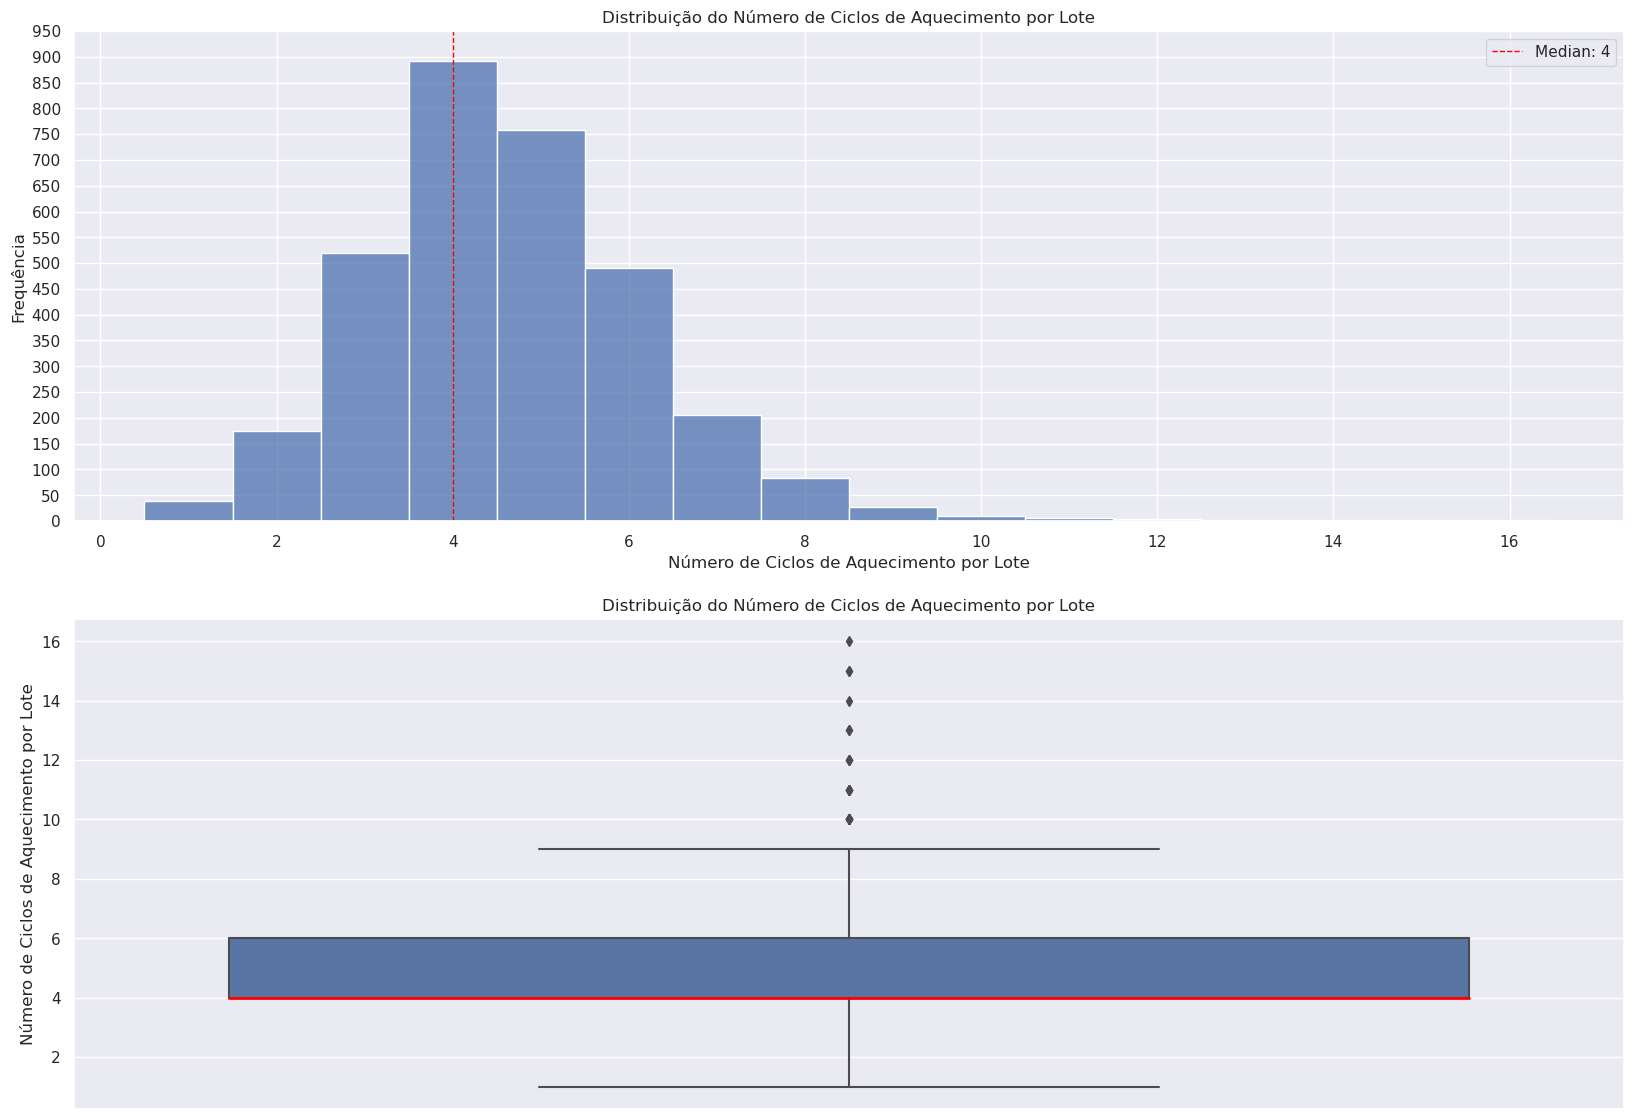

    cycles_per_batch  frequency  relative_frequency
0                  4        892            0.277536
1                  5        759            0.236154
2                  3        520            0.161792
3                  6        490            0.152458
4                  7        205            0.063783
5                  2        174            0.054138
6                  8         84            0.026136
7                  1         39            0.012134
8                  9         28            0.008712
9                 10          9            0.002800
10                11          5            0.001556
11                12          3            0.000933
12                13          2            0.000622
13                15          2            0.000622
14                14          1            0.000311
15                16          1            0.000311


In [13]:
fig, axes = plt.subplots(nrows=2,ncols=1,figsize=(20,14))

sns.histplot(x=heating_cycles_per_key,discrete=True,ax=axes[0])

axes[0].set_title("Distribuição do Número de Ciclos de Aquecimento por Lote")
axes[0].set_xlabel("Número de Ciclos de Aquecimento por Lote")
axes[0].set_ylabel("Frequência")

stepsize = 50
start, end = axes[0].get_ylim()
axes[0].set_yticks(np.arange(start, end + stepsize, stepsize))

median_val = heating_cycles_per_key.median()

axes[0].axvline(
    x=median_val,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"Median: {median_val:.0f}"
)
axes[0].legend()

sns.boxplot(y=data_arc_en['key'].value_counts(),ax=axes[1],medianprops={"color": "red", "linewidth": 2})

axes[1].set_title("Distribuição do Número de Ciclos de Aquecimento por Lote")
axes[1].set_ylabel("Número de Ciclos de Aquecimento por Lote")

plt.show()

print(heating_cycles_frequency_table)

In [14]:
print(f"Frequência Relativa de Lotes com 4 ou 5 Ciclos de Aquecimento: {heating_cycles_per_key.isin([4,5]).mean()*100:.2f}%")


Frequência Relativa de Lotes com 4 ou 5 Ciclos de Aquecimento: 51.37%


Como podemos observar nos gráficos acima, a maioria dos lotes ficam entre 2 e 8 ciclos de aquecimento, com uma grande concentração de Lotes que receberam 4 ou 5 ciclos de aquecimento, representando 51% dos lotes (como podemos ver em nossa tabela de frequências). A mediana está assinalada em vermelho e tem valor de  4 ciclos por Lote.

Existem números significativos de lotes que precisam de 2, 3, 6, 7 ou 8 ciclos de aquecimento, mas os Lotes que tem apenas 1 ciclo de aquecimento ou 9 são uma pequena minoria, com menos de 40 lotes apresentando esses valores. Já os lotes com mais de 10 ciclos de aquecimento são extremamente raros se comparados com o resto do dataset, quase não aparecendo no nosso gráfico e registrando menos de 10 lotes para cada um desses números de ciclos de aquecimento.

### Analisando as Colunas Temporais à Fundo

#### Coluna "arc_heating_start"

Ao carregar os dados, usamos o parâmetro **parse_dates** na função **read_csv**. Essa função converte os dados para o tipo **datetime** ao carregar o DataFrame original, mas se houverem valores inválidos na coluna, os dados são carregados como strings (tipo de dados **object** na versão de Pandas utilizada nesse projeto). Como a coluna foi convertida para **datetime** corretamente, sabemos que todos os valores da coluna "arc_heating_start" são válidos.

Agora vamos verificar os valores duplicados. É possível que existam valores duplicados caso um refino tenha ocorrido enquanto outro também estava acontecendo. Isso significa que encontrar linhas com valores diferentes de chaves "key" é aceitável. Se existirem valores duplicados para a mesma chave "key", teremos que investigar.

In [15]:
data_arc_en[data_arc_en.loc[:,"arc_heating_start"].duplicated(keep=False)]

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
4872,1051,2019-06-10 22:02:03,2019-06-10 22:06:02,1.040376,0.635608
4876,1052,2019-06-10 22:02:03,2019-06-10 22:04:31,0.623495,0.508767


O único valor duplicado da coluna 'arc_heating_start' está presente com chaves de números diferentes, o que significa que são ciclos de aquecimentos de processos de refino secundário separados mas que ocorreram ao mesmo tempo (por coincidência, os ciclos de aquecimento se iniciaram exatamento ao mesmo tempo). Isso não é um problema e esses valores devem ser mantidas em seus estados originais.

#### Coluna "arc_heating_end"

Ao carregar os dados, usamos o parâmetro **parse_dates** na função **read_csv**. Essa função converte os dados para o tipo **datetime** ao carregar o DataFrame original, mas se houverem valores inválidos na coluna, os dados são carregados como strings (tipo de dados **object** na versão de Pandas utilizada nesse projeto). Como a coluna foi convertida para **datetime** corretamente, sabemos que todos os valores da coluna "arc_heating_end" são válidos.

#### Análise da Duração dos Ciclos de Aquecimento

In [16]:
data_arc_en['arc_heating_interval'] = (data_arc_en['arc_heating_end'] - data_arc_en['arc_heating_start']).dt.total_seconds()


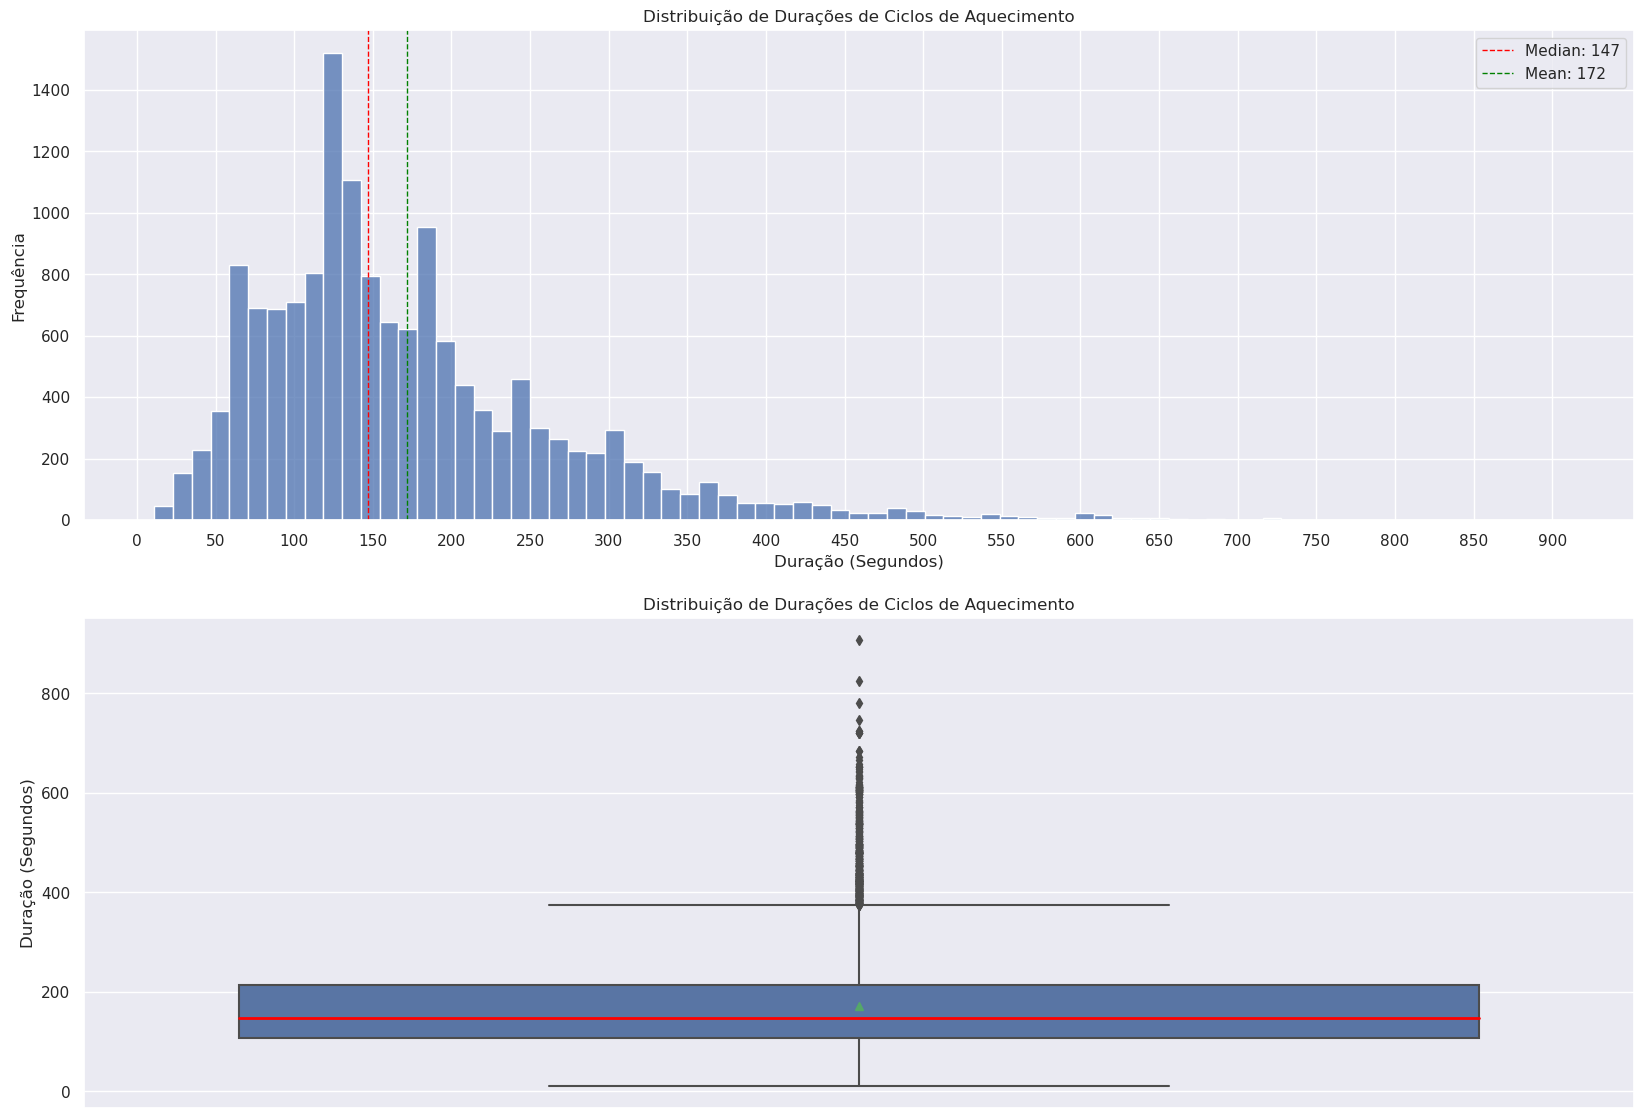

In [17]:
fig, axes = plt.subplots(2,1,figsize=(20,14))

sns.histplot(data=data_arc_en,x='arc_heating_interval',ax=axes[0],discrete=False,bins=75)

axes[0].set_title("Distribuição de Durações de Ciclos de Aquecimento")
axes[0].set_xlabel("Duração (Segundos)")
axes[0].set_ylabel("Frequência")
start = 0
end = 900
stepsize=50
axes[0].set_xticks(np.arange(start,end+stepsize,stepsize))



median_val = data_arc_en['arc_heating_interval'].median()
axes[0].axvline(
    x=median_val,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"Median: {median_val:.0f}"
)

mean_val = data_arc_en['arc_heating_interval'].mean()
axes[0].axvline(
    x=mean_val,
    color="green",
    linestyle="--",
    linewidth=1,
    label=f"Mean: {mean_val:.0f}"
)

axes[0].legend()


sns.boxplot(y=data_arc_en['arc_heating_interval'],ax=axes[1],medianprops={"color":"red","linewidth":2},showmeans=True)

axes[1].set_title("Distribuição de Durações de Ciclos de Aquecimento")
axes[1].set_ylabel("Duração (Segundos)")

plt.show()



Como podemos observar, existe uma variabilidade da na duração dos ciclos de aquecimento, com ciclos durando de 25 até mesmo mais de 600 segundos, embora a concentração de durações a por volta de 65 à 200 segundos. Como temos contribuições diversas, isso deve ser uma fonte rica de informações para nossos modelos entenderem padrões de aquecimento e suas relações diretas com as temperaturas medidas.

####  Coluna "key"

Por definição, é esperado que existam muitas linhas com o mesmo valor nessa coluna, uma vez que cada linha corresponde a um ciclo de aquecimento e um lote de refino secundário pode ter muitos ciclos de aquecimento.

Como vimos anteriormente, não existem valores negativos na coluna **key** o que significa que todos os seus valores são válidos.

#### Coluna "active_power"

Como estabelecido anteriormente, todos os valores dessa coluna são válidos

#### Coluna "reactive_power"

Vamos verificar os valores valores negativos dessa coluna

In [18]:
data_arc_en.loc[data_arc_en["reactive_power"] <=0]

,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval
9780,2116,2019-07-24 00:44:48,2019-07-24 00:46:37,0.495782,-715.504924,109.0


Existe apenas um valor negativo na coluna reactive_power. Embora não saibamos a natureza desses dados, não seria errado assumir que apenas um valor negativo dentre mais de 14.000 possa significar que é um valor errado, mas não temos como provar isso. Iremos lidar com esse valor posteriormente ao preparar os dados para os modelos.

In [19]:
data_arc_en['key'].nunique()

3214

## Dados sobre o Fornecimento de Materiais a Granel (data_bulk_en)

Esse dataset representa o volume de cada material que foi adicionado ao Forno-Panela em volumes. Cada coluna representa um material. Cada linha representa um lote de refino secundário. Esperamos ver apenas uma linha para cada chave "key" nesse dataset.

In [20]:
data_bulk_en.head()

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15
0,1,NaN,NaN,NaN,43.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.0,NaN,150.0,154.0
1,2,NaN,NaN,NaN,73.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.0,NaN,149.0,154.0
2,3,NaN,NaN,NaN,34.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,205.0,NaN,152.0,153.0
3,4,NaN,NaN,NaN,81.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,207.0,NaN,153.0,154.0
4,5,NaN,NaN,NaN,78.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,203.0,NaN,151.0,152.0


In [21]:
data_bulk_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   key      3129 non-null   int64  
 1   bulk_1   252 non-null    float64
 2   bulk_2   22 non-null     float64
 3   bulk_3   1298 non-null   float64
 4   bulk_4   1014 non-null   float64
 5   bulk_5   77 non-null     float64
 6   bulk_6   576 non-null    float64
 7   bulk_7   25 non-null     float64
 8   bulk_8   1 non-null      float64
 9   bulk_9   19 non-null     float64
 10  bulk_10  176 non-null    float64
 11  bulk_11  177 non-null    float64
 12  bulk_12  2450 non-null   float64
 13  bulk_13  18 non-null     float64
 14  bulk_14  2806 non-null   float64
 15  bulk_15  2248 non-null   float64
dtypes: float64(15), int64(1)
memory usage: 391.2 KB


Todas as colunas, exceto 'key', tem valores ausentes. Isso é esperado uma vez que cada coluna Bulk representa um material que foi adicionado ao aço e nem todoso os materiais serão adicionados a todo ciclo de refino secundário. Esses valores podem ser substituídos por 0 caso um de nossos modelos precise ser treinado sem valores nulos.

Existem 3129 linhas no conjunto de dados de materiais a granel, representando um total de 3129 Lotes completos de Refino Secundário. Vale lembrar que nosso dataset de eletrodos tinha 3214 ciclos completos de Refino Secundário (chaves 'key' unívocas). Isso pode significar que alguns ciclos de Refino Secundário não receberam materiais a serem adicionados, mas precisaremos investigar antes de preparar os dados para os modelos.

Também existem 16 colunas:
- "key" - representa uma chave que corresponde a um ciclo inteiro de refino secundário desde a introdução do aço líquido ao Forno-Panela até a autorização para lingotamento.
- "bulk_1" até "bulk_15" - representam os volumes de cada material que foi adicionado durante um ciclo completo de Refino Secundário.

In [22]:
data_bulk_en.describe()

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15
count,3129.000000,252.000000,22.000000,1298.000000,1014.000000,77.000000,576.000000,25.000000,1.0,19.000000,176.000000,177.000000,2450.000000,18.000000,2806.000000,2248.000000
mean,1624.383509,39.242063,253.045455,113.879045,104.394477,107.025974,118.925347,305.600000,49.0,76.315789,83.284091,76.819209,260.471020,181.111111,170.284747,160.513345
std,933.337642,18.277654,21.180578,75.483494,48.184126,81.790646,72.057776,191.022904,NaN,21.720581,26.060347,59.655365,120.649269,46.088009,65.868652,51.765319
min,1.000000,10.000000,228.000000,6.000000,12.000000,11.000000,17.000000,47.000000,49.0,63.000000,24.000000,8.000000,53.000000,151.000000,16.000000,1.000000
25%,816.000000,27.000000,242.000000,58.000000,72.000000,70.000000,69.750000,155.000000,49.0,66.000000,64.000000,25.000000,204.000000,153.250000,119.000000,105.000000
50%,1622.000000,31.000000,251.500000,97.500000,102.000000,86.000000,100.000000,298.000000,49.0,68.000000,86.500000,64.000000,208.000000,155.500000,151.000000,160.000000
75%,2431.000000,46.000000,257.750000,152.000000,133.000000,132.000000,157.000000,406.000000,49.0,70.500000,102.000000,106.000000,316.000000,203.500000,205.750000,205.000000
max,3241.000000,185.000000,325.000000,454.000000,281.000000,603.000000,503.000000,772.000000,49.0,147.000000,159.000000,313.000000,1849.000000,305.000000,636.000000,405.000000


In [23]:
print(f"Porcentagem de Lotes que Receberam Adições de Cada Material:\n{(data_bulk_en.drop('key',axis=1).count() / data_bulk_en['key'].count()).round(4)}")

Porcentagem de Lotes que Receberam Adições de Cada Material:
bulk_1     0.0805
bulk_2     0.0070
bulk_3     0.4148
bulk_4     0.3241
bulk_5     0.0246
bulk_6     0.1841
bulk_7     0.0080
bulk_8     0.0003
bulk_9     0.0061
bulk_10    0.0562
bulk_11    0.0566
bulk_12    0.7830
bulk_13    0.0058
bulk_14    0.8968
bulk_15    0.7184
dtype: float64


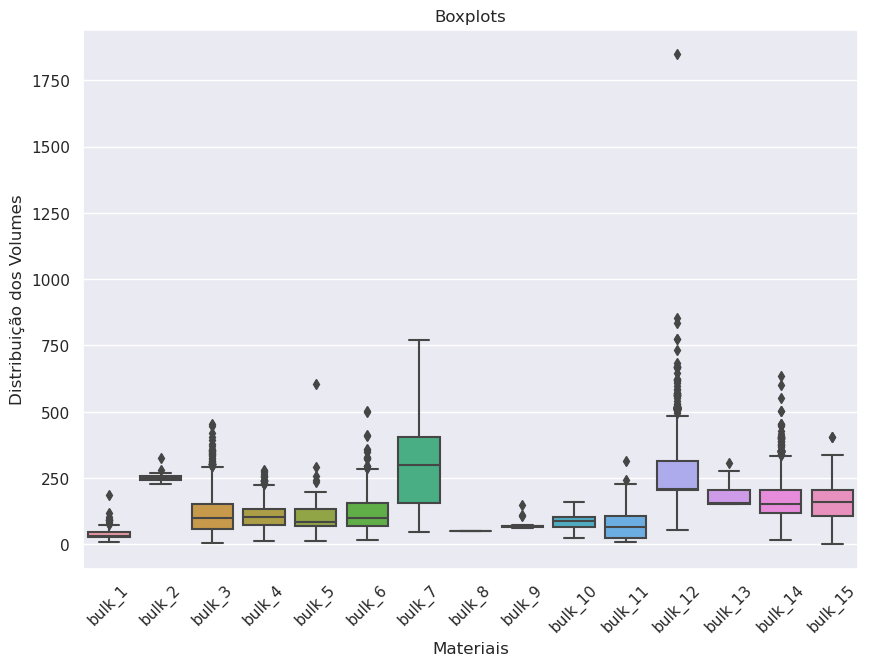

In [24]:
fig, ax = plt.subplots(figsize=(10,7))

sns.boxplot(data=data_bulk_en.drop("key",axis=1),ax=ax)

ax.set_title("Boxplots")
ax.set_xlabel("Materiais")
ax.set_ylabel("Distribuição dos Volumes")
ax.set_xticklabels(ax.get_xticklabels(),rotation=45)

plt.show()



Como observamos, existem materiais que são adicionados com muito mais frequência em Lotes do que outros. Os materiais **bulk_12**, **bulk_14** e **bulk_15** são adicionados na maioria dos Lotes, com frequência de adição de 78%, 90% e 72% dos Lotes respectivamente. Bulk_3, bulk_4 e bulk_6 também são materiais com adições em números considerais de lotes com frequências de 41%, 32% e 18% respectivamente. Os outros materiais não são adicionados com muita frequência aos Lotes, embora o volume de adições totais a cada Lote que recebeu adições tenha variações bastante diferentes para cada material, como bulk_7 que foi adicionado a menos de 1% dos Lotes mas tem distribuição de volumes bastante dispersa. Podemos considerar o valor predidtivo de cada uma dessas variáveis posteriormente antes de preparar os dados para os modelos, mas desde já fica claro que bulk_8 possivelmente não trará muito valor por se tratar de um material que foi adicionado apenas a um único Lote de Refino Secundário.

## Dados sobre os tempos de Fornecimento de Material a Granel

In [25]:
data_bulk_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   key      3129 non-null   int64         
 1   bulk_1   252 non-null    datetime64[ns]
 2   bulk_2   22 non-null     datetime64[ns]
 3   bulk_3   1298 non-null   datetime64[ns]
 4   bulk_4   1014 non-null   datetime64[ns]
 5   bulk_5   77 non-null     datetime64[ns]
 6   bulk_6   576 non-null    datetime64[ns]
 7   bulk_7   25 non-null     datetime64[ns]
 8   bulk_8   1 non-null      datetime64[ns]
 9   bulk_9   19 non-null     datetime64[ns]
 10  bulk_10  176 non-null    datetime64[ns]
 11  bulk_11  177 non-null    datetime64[ns]
 12  bulk_12  2450 non-null   datetime64[ns]
 13  bulk_13  18 non-null     datetime64[ns]
 14  bulk_14  2806 non-null   datetime64[ns]
 15  bulk_15  2248 non-null   datetime64[ns]
dtypes: datetime64[ns](15), int64(1)
memory usage: 391.2 KB


Todas as colunas, exceto 'key', tem valores ausentes. Isso é esperado uma vez que cada coluna Bulk representa um material que foi adicionado ao aço e nem todoso os materiais serão adicionados a todo ciclo de refino secundário.

Existem 3129 linhas no conjunto de dados de tempos de fornecimento de materiais a granel, representando um total de 3129 Lotes completos de Refino Secundário. Vale lembrar que nosso dataset de eletrodos tinha 3214 ciclos completos de Refino Secundário (chaves 'key' unívocas). Isso pode significar que alguns ciclos de Refino Secundário não receberam materiais a serem adicionados, mas precisaremos investigar antes de preparar os dados para os modelos.

Também existem 16 colunas:
- "key" - representa uma chave que corresponde a um Lote inteiro de refino secundário desde a introdução do aço líquido ao Forno-Panela até a autorização para lingotamento.
- "bulk_1" até "bulk_15" - representam as data-hora (timestamp) em que cada material adicionado a um Lote completo de Refino Secundário.

## Dados sobre o Processo de Purga de Gás

In [26]:
data_gas_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3239 entries, 0 to 3238
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3239 non-null   int64  
 1   gas_1   3239 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 50.7 KB


Não existem valores ausentes nesse dataset.

Existem 3239 linhas no conjunto de dados de tempos de gás, representando um total de 3239 Lotes completos de Refino Secundário. Vale lembrar que nosso dataset de eletrodos tinha 3214 ciclos completos de Refino Secundário (chaves 'key' unívocas). Isso pode significar que alguns ciclos de Refino Secundário não receberam purga de gás, mas precisaremos investigar antes de preparar os dados para os modelos.

Também existem 2 colunas:
- "key" - representa uma chave que corresponde a um Lote refino secundário desde a introdução do aço líquido ao Forno-Panela até a autorização para lingotamento.
- "gas_1" - representa o total de gás adicionado ao Lote

NOTA:

Uma complicação clara desse dataset é que não temos a data-hora da adição da purga de gás aos Lotes. Isso significa que não temos como saber quando o gás foi adicionado aos Lotes. **gas_1** representa puramente o total de gás adicionado ao Lote completo. É possível que esse dataset deva ser ignorado e que os valores de purga de gás não sejam úteis para o nosso modelo uma vez que não poderemos incluir esse valor a nenhum momento específico do aquecimento do Lote. Essa é uma limitação que não podemos ignorar e ficaria difícil justificar algum tipo de separação desses dados como uma "divisão" simples do total de purga de gás em cada ciclo de aquecimento de um mesmo Lote de aquecimento.

In [27]:
data_gas_en.describe()

,key,gas_1
count,3239.000000,3239.000000
mean,1621.861377,11.002062
std,935.386334,6.220327
min,1.000000,0.008399
25%,812.500000,7.043089
50%,1622.000000,9.836267
75%,2431.500000,13.769915
max,3241.000000,77.995040


<AxesSubplot:xlabel='gas_1', ylabel='Count'>

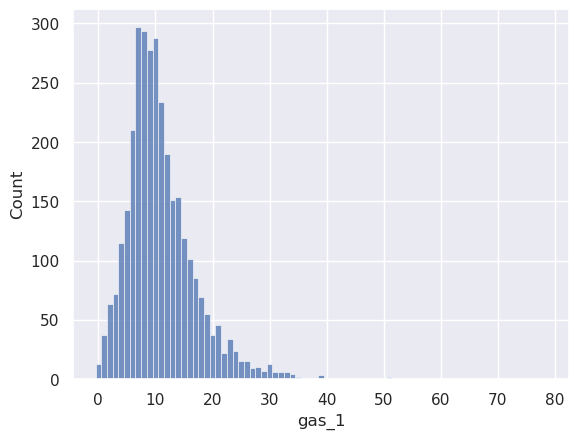

In [28]:
sns.histplot(data_gas_en,x='gas_1',discrete=True)

Os dados da purga de gás não são muito dispersos, se concentrado ao redor de 5 a 15 para cada Lote. Imagino que essa relação possa ter uma correlação direta com o número de aquecimentos por Lote também, o que seria um possível motivo para matermos a ideia de não usar os dados de purga de gás. A correlação entre números de ciclo de aquecimento e maior adição de gás para purga poderia significar que a purga é adicionada multiplas vezes, talvez toda vez que o material é aquecido ou toda vez que existe algum tipo de adição de materiais ao Lote. Embora não possamos comprovar esse fato, isso significaria que é muito importante saber exatamente quando a purga de gás ocorreu. De qualquer forma, não saber quando essa purga ocorreu dificulta o uso dessa variável para nosso modelo que depende de data-hora para saber quando cada ação foi tomada durante um ciclo de aquecimento.

## Dados sobre os Registros de Medições de Temperatura

In [29]:
data_temp_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15907 entries, 0 to 15906
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   key            15907 non-null  int64         
 1   sampling_time  15907 non-null  datetime64[ns]
 2   temperature    13006 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 372.9 KB


Existem valores nulos na coluna **temperature**. Isso significa que as temperaturas foram medidas mas não temos acessos aos seus valores. Possivelmente teremos que ignorar essas linhas para poder treinar nossos modelos uma vez que ausência de temperatura significa não termos como treinar o modelo para prever aquela temperatura.

Existem 15907 linhas no conjunto de dados de temperatura, representando um total de 15907 medições de temperatura. Cada medição de temperatura tem uma temperatura única relacionada mas cada Lote de Refino Secundário, representados por **key** podem receber múltiplas medições de temperatura.

Também existem 3 colunas:
- "key" - representa uma chave que corresponde a um Lote refino secundário desde a introdução do aço líquido ao Forno-Panela até a autorização para lingotamento.
- "sampling_time" - representa a data-hora em que aquela medição de temperatura ocorreu.
- "temperature" - representa a temperatura em Celsius relacionada aquela medição.

In [30]:
sampling_per_key = data_temp_en.groupby('key').size()

sampling_per_key.describe()

count    3216.000000
mean        4.946206
std         1.793169
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        16.000000
dtype: float64

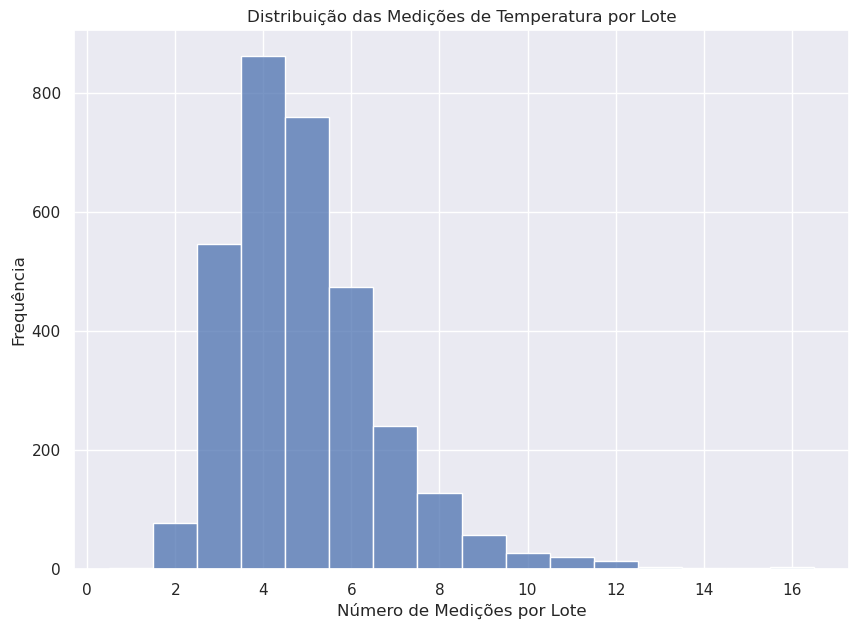

In [31]:
fig, ax = plt.subplots(figsize=(10,7))

sns.histplot(x = sampling_per_key,discrete=True,ax=ax)

ax.set_title("Distribuição das Medições de Temperatura por Lote")
ax.set_xlabel("Número de Medições por Lote")
ax.set_ylabel("Frequência")

plt.show()

In [32]:
sampling_frequency_table = data_temp_en.groupby("key").size().rename("samplings")

print(f"Média de medições de temperatura por Lote de Refino Secundário: {sampling_frequency_table.mean():.2f}")
print(f"Mínimo de medições de temperatura por Lote de Refino Secundário: {sampling_frequency_table.min():.2f}")
print(f"Máximo de medições de temperatura por Lote de Refino Secundário: {sampling_frequency_table.max():.2f}")


Média de medições de temperatura por Lote de Refino Secundário: 4.95
Mínimo de medições de temperatura por Lote de Refino Secundário: 1.00
Máximo de medições de temperatura por Lote de Refino Secundário: 16.00


In [33]:
sampling_frequency_table = (
    sampling_frequency_table.value_counts()
    .rename_axis("samplings_per_batch", axis=0)
    .reset_index(name="frequency")
)

sampling_frequency_table["relative_frequency"] = sampling_frequency_table["frequency"] / sampling_frequency_table["frequency"].sum()

In [34]:
sampling_frequency_table

,samplings_per_batch,frequency,relative_frequency
0,4,862,0.268035
1,5,759,0.236007
2,3,545,0.169465
3,6,473,0.147077
4,7,240,0.074627
5,8,128,0.039801
6,2,78,0.024254
7,9,57,0.017724
8,10,27,0.008396
9,11,21,0.006530


In [35]:
print(f"Frequência Relativa de Lotes com 4 ou 5 Medições de Temperaturao: {sampling_frequency_table.loc[sampling_frequency_table['samplings_per_batch'].isin([4,5]),'relative_frequency'].sum()*100:.2f}")

Frequência Relativa de Lotes com 4 ou 5 Medições de Temperaturao: 50.40


Como podemos observar, todos os Lotes receberam pelo menos uma medição de temperatura e chegaram a até 16 medições de temperatura A maioria dos Lotes teve 4 ou 5 medições temperatura, sendo esses cerca de 50% dos Lotes para medições.

Embora esses valores sejam muito parecidos com os valores da média e do maior número de ciclos de aquecimento, não podemos dizer que esses valores tem uma correlação direta entre si. Precisariamos entender a correlação dessas duas distribuições para cada um dos Lotes.

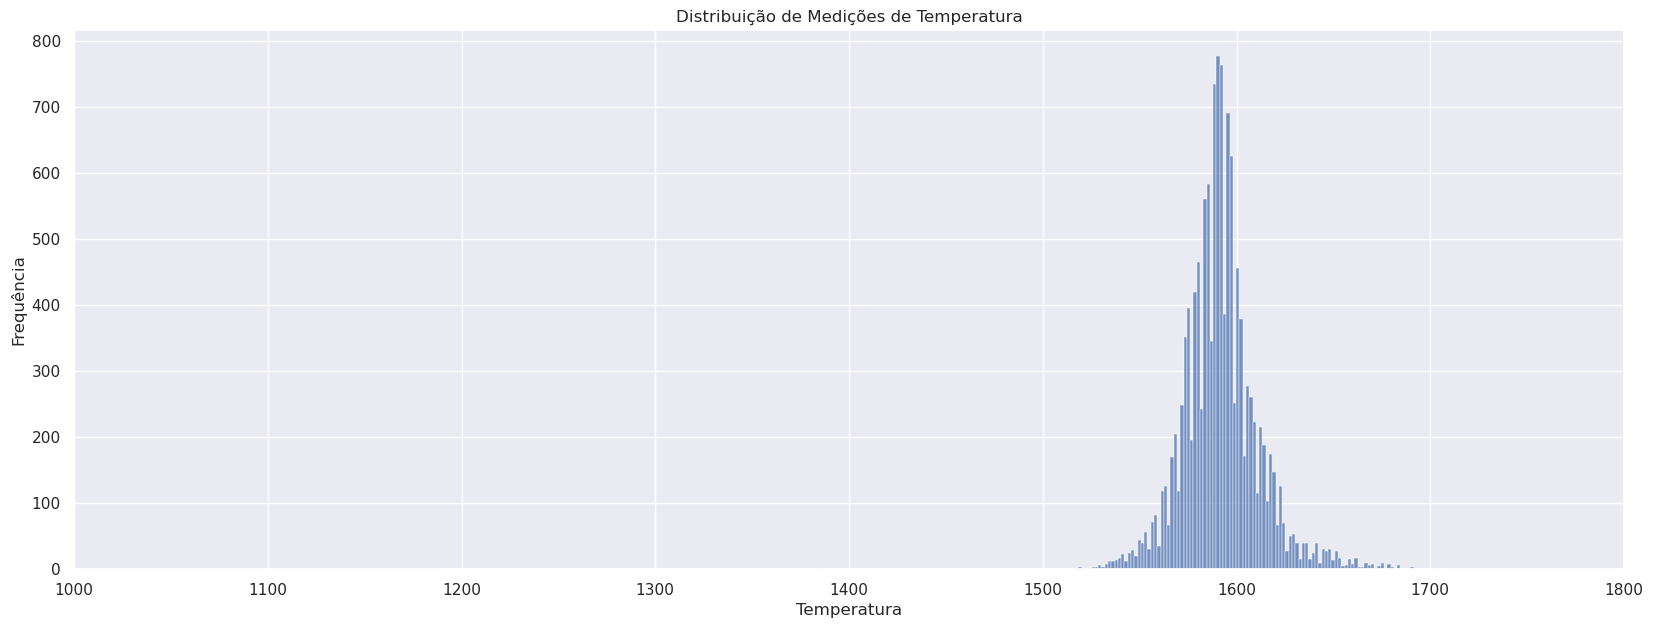

In [36]:
fig,ax = plt.subplots(figsize=(20,7))

sns.histplot(data_temp_en,x='temperature',discrete=False,ax=ax)

ax.set_title("Distribuição de Medições de Temperatura")
ax.set_xlabel("Temperatura")
ax.set_ylabel("Frequência")

stepsize=100
start = 1000
end = 1800

ax.set_xticks(np.arange(start,end+stepsize,stepsize))


plt.show()

In [37]:
data_temp_en['temperature'].describe()

count    13006.000000
mean      1591.840920
std         21.375851
min       1191.000000
25%       1581.000000
50%       1591.000000
75%       1601.000000
max       1705.000000
Name: temperature, dtype: float64

A média de temperaturas que temos é de $1591.84^oC$ enquanto os 50% centrais dos nossos dados vão de $1581^oC$ até $1601^oC$. Me parece que a Steelproof procura manter a temperatura por volta desses valores que devem ser os ideais. Segundo Rizzo 2006 e Rocha 2026, a temperatura ideal de fusão do aço é de $1600^oC$. Isso não significa que a temperatura ideal dentro do Forno Panela ou a temperatura ideal final para lingoteamento do aço seja exatamente $1600^oC$ pois existe muita variação entre os diferentes tipos de aço e produtos finais desejados. Mas essa é uma boa referência para termos em mente.

Vemos também que nossos dados vão de $1191^oC$ até $1705^oC$, o que mostra que existe bastante variação nas temperaturas independente de boas práticas serem seguidas. O desvio padrão de $21.38^oC$ mostra uma leve dispersão nos dados.

As temperaturas baixas são provavelmente erros de registro ou medição, uma vez que o aço começa a se solidificar entre 1400 à 1500 C. Teremos que investigar uma temperatura mínima para definir como um limite e remover as temperaturas abaixo desse limite. Idealmente, a Steelproof nos forneceria uma temperatura mínima baseada em seus limites operacionais.

Número de medições de temperatura ausentes: 2901
Data-hora mínima da distribuição de todas as temperaturas: 2019-05-03 11:16:18
Data-hora mínima da distribuição de todas as temperaturas: 2019-09-01 04:38:08
Data-hora mínima da distribuição de temperaturas ausentes: 2019-08-06 03:24:43
Data-hora máxima da distribuição de temperaturas ausentes: 2019-09-01 04:38:08


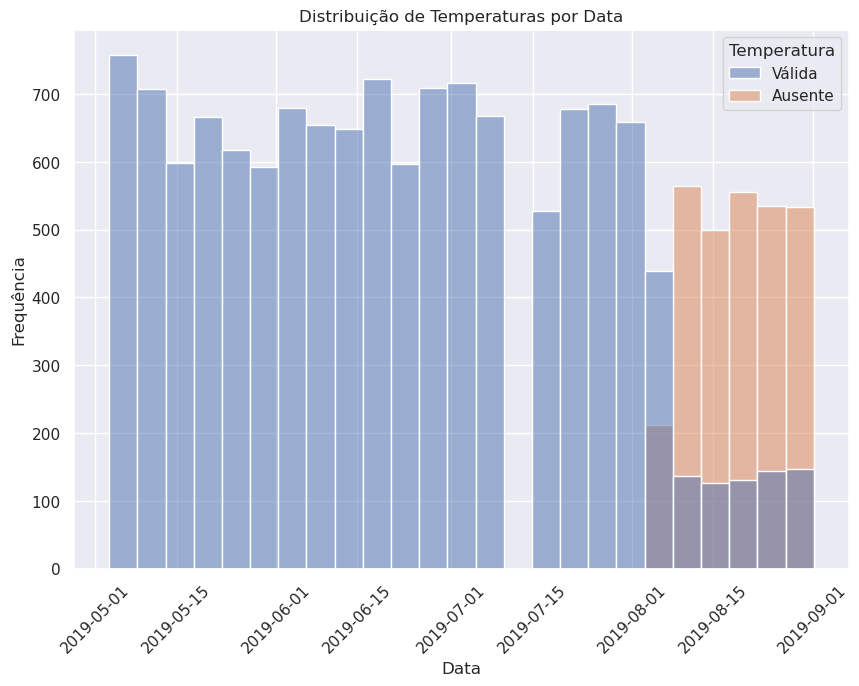

In [38]:
data_temp_en['missing_temp'] = np.where(data_temp_en['temperature'].isna(), "missing_temp", "present_temp")

print("Número de medições de temperatura ausentes:",(data_temp_en['missing_temp'] == 'missing_temp').sum())

print("Data-hora mínima da distribuição de todas as temperaturas:",data_temp_en.loc[:,'sampling_time'].min())
print("Data-hora mínima da distribuição de todas as temperaturas:",data_temp_en.loc[:,'sampling_time'].max())
print("Data-hora mínima da distribuição de temperaturas ausentes:",data_temp_en.loc[data_temp_en['missing_temp'] == 'missing_temp','sampling_time'].min())
print("Data-hora máxima da distribuição de temperaturas ausentes:",data_temp_en.loc[data_temp_en['missing_temp'] == 'missing_temp','sampling_time'].max())

fig,ax = plt.subplots(figsize=(10,7))

sns.histplot(data=data_temp_en,x='sampling_time',ax=ax,hue='missing_temp')

ax.set_title("Distribuição de Temperaturas por Data")
ax.set_xlabel("Data")
ax.set_ylabel("Frequência")

legend = ax.get_legend()

for handle, new_label in zip(
    legend.get_texts(),
    ['Válida', 'Ausente']
):
    handle.set_text(new_label)

legend.set_title('Temperatura')

plt.xticks(rotation=45)

plt.show()

Existem 2901 temperaturas nulas que teremos que tratar ao analisar os dados. Como essa variável é o nosso objetivo, não podemos simplesmente imputar dados nessa coluna. Provavelmente teremos que remover essas temperaturas e lidar com o novo dataset sem as mesmas.

Essas temperaturas ausentes estão presentes no final do dataset, entre 2019-08-05 até 2019-09-01. Ainda existem algumas temperaturas válidas no final do dataset, mas essas estão em menor proporção que as temperaturas ausentes.

In [39]:
data_temp_en['key'].nunique()

3216

As medições de temperatura correspondem a 3216 Lotes de Refino Secundário, o que significa que existem muitos Lotes com mais de uma medição de temperatura.

## Dados sobre o Fornecimento de Materiais em Arame

Esses dados representa os os volumes de materiais que foram adicionados em forma de arames com núcleo de algum material que é útil para o controle da composição química final do aço.

In [40]:
data_wire_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3081 non-null   int64  
 1   wire_1  3055 non-null   float64
 2   wire_2  1079 non-null   float64
 3   wire_3  63 non-null     float64
 4   wire_4  14 non-null     float64
 5   wire_5  1 non-null      float64
 6   wire_6  73 non-null     float64
 7   wire_7  11 non-null     float64
 8   wire_8  19 non-null     float64
 9   wire_9  29 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 240.8 KB


Todas as colunas, exceto 'key', tem valores ausentes. Isso é esperado uma vez que cada coluna Wire representa um material que foi adicionado ao aço e nem todos os materiais serão adicionados a todo ciclo de refino secundário. Esses valores podem ser substituídos por 0 caso um de nossos modelos precise ser treinado sem valores nulos.

Existem 3081 linhas no conjunto de dados de materiais em arame, representando um total de 3081 Lotes completos de Refino Secundário. Vale lembrar que nosso dataset de eletrodos tinha 3214 ciclos completos de Refino Secundário (chaves 'key' unívocas). Isso pode significar que alguns ciclos de Refino Secundário não receberam materiais a serem adicionados, mas precisaremos investigar antes de preparar os dados para os modelos.

Também existem 10 colunas:
- "key" - representa uma chave que corresponde a Lote inteiro de refino secundário desde a introdução do aço líquido ao Forno-Panela até a autorização para lingotamento.
- "wire_1" até "wire_9" - representam os volumes de cada material que foi adicionado ao Lote completo de Refino Secundário.

In [41]:
data_wire_en.describe()

,key,wire_1,wire_2,wire_3,wire_4,wire_5,wire_6,wire_7,wire_8,wire_9
count,3081.000000,3055.000000,1079.000000,63.000000,14.000000,1.000,73.000000,11.000000,19.000000,29.000000
mean,1623.426485,100.895853,50.577323,189.482681,57.442841,15.132,48.016974,10.039007,53.625193,34.155752
std,932.996726,42.012518,39.320216,99.513444,28.824667,NaN,33.919845,8.610584,16.881728,19.931616
min,1.000000,1.918800,0.030160,0.144144,24.148801,15.132,0.034320,0.234208,45.076721,4.622800
25%,823.000000,72.115684,20.193680,95.135044,40.807002,15.132,25.053600,6.762756,46.094879,22.058401
50%,1619.000000,100.158234,40.142956,235.194977,45.234282,15.132,42.076324,9.017009,46.279999,30.066399
75%,2434.000000,126.060483,70.227558,276.252014,76.124619,15.132,64.212723,11.886057,48.089603,43.862003
max,3241.000000,330.314424,282.780152,385.008668,113.231044,15.132,180.454575,32.847674,102.762401,90.053604


Porcentagem de Lotes que Receberam Adições de Cada Material:
wire_1    0.9916
wire_2    0.3502
wire_3    0.0204
wire_4    0.0045
wire_5    0.0003
wire_6    0.0237
wire_7    0.0036
wire_8    0.0062
wire_9    0.0094
dtype: float64


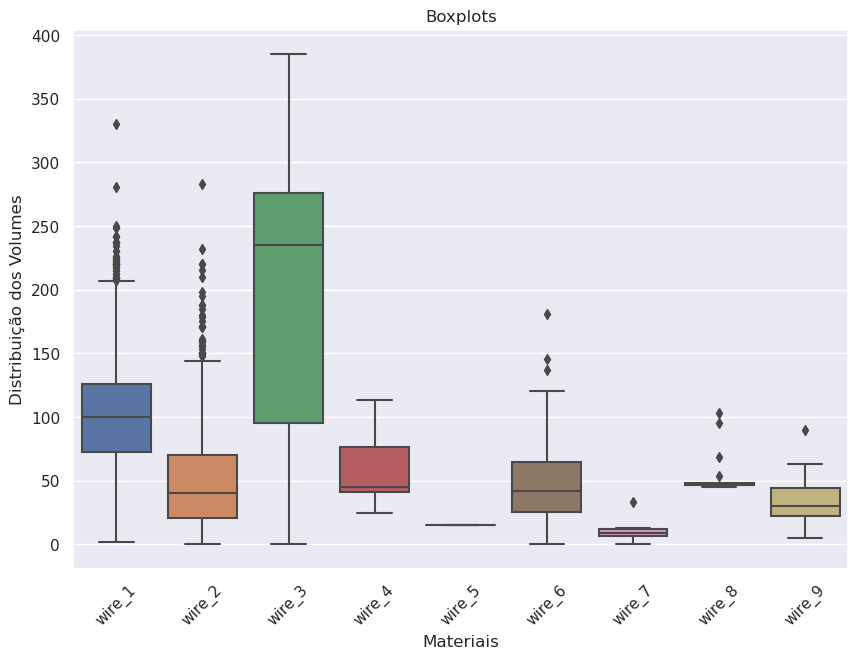

In [42]:
print(f"Porcentagem de Lotes que Receberam Adições de Cada Material:\n{(data_wire_en.drop('key',axis=1).count() / data_wire_en['key'].count()).round(4)}")

fig, ax = plt.subplots(figsize=(10,7))

sns.boxplot(data=data_wire_en.drop("key",axis=1),ax=ax)

ax.set_title("Boxplots")
ax.set_xlabel("Materiais")
ax.set_ylabel("Distribuição dos Volumes")
ax.set_xticklabels(ax.get_xticklabels(),rotation=45)

plt.show()



Como podemos observar maioria dos Lotes recebeu o material **wire_1** que esteve presente em 99% dos lotes. Em segundo lugar, wire_2 foi adicionado a 35% dos Lotes. Todos os outros materiais foram adicionados raramente, nenhum passando de 2.4% dos Lotes. Em números absolutos, o material wire_5 foi adicionado a apenas um Lote enquanto wire_3 foi adicionado a 63 Lotes e é o material com maior número de adições depois dos materiais wire_1 e wire_2 que foram adicionados em mais 3055 e 1071 lotes respectivamente. Isso significa que teremos que entender qual será o valor dessas variáveis para nosso modelo preditivo antes de treiná-lo.

## Dados sobre os tempos de Fornecimento de Materiais em Arame

In [43]:
data_wire_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   key     3081 non-null   int64         
 1   wire_1  3055 non-null   datetime64[ns]
 2   wire_2  1079 non-null   datetime64[ns]
 3   wire_3  63 non-null     datetime64[ns]
 4   wire_4  14 non-null     datetime64[ns]
 5   wire_5  1 non-null      datetime64[ns]
 6   wire_6  73 non-null     datetime64[ns]
 7   wire_7  11 non-null     datetime64[ns]
 8   wire_8  19 non-null     datetime64[ns]
 9   wire_9  29 non-null     datetime64[ns]
dtypes: datetime64[ns](9), int64(1)
memory usage: 240.8 KB


Todas as colunas, exceto 'key', tem valores ausentes. Isso é esperado uma vez que cada coluna Bulk representa um material que foi adicionado ao aço e nem todoso os materiais serão adicionados a todo ciclo de refino secundário.

Existem 3081 linhas no conjunto de dados de tempos de fornecimento de materiais em arame, representando um total de 3081 Lotes completos de Refino Secundário. Vale lembrar que nosso dataset de eletrodos tinha 3214 ciclos completos de Refino Secundário (chaves 'key' unívocas). Isso pode significar que alguns ciclos de Refino Secundário não receberam materiais a serem adicionados, mas precisaremos investigar antes de preparar os dados para os modelos.

Também existem 10 colunas:
- "key" - representa uma chave que corresponde a um Lote inteiro de refino secundário desde a introdução do aço líquido ao Forno-Panela até a autorização para lingotamento.
- "wire_1" até "wire_9" - representam as data-hora (timestamp) em que cada material foi adicionado a um Lote completo de Refino Secundário.

## ANÁLISES DOS DADOS CONJUNTOS

Primeiramente, vamos analisar a relação entre as medições de temperatura e os ciclos de aquecimento.

In [44]:
last_temp:pd.DataFrame  = data_temp_en.groupby('key')[['sampling_time']].max()

last_heating:pd.DataFrame = (
    data_arc_en.loc[
        data_arc_en.groupby('key')['arc_heating_end'].idxmax(),
        ['key', 'arc_heating_start', 'arc_heating_end']
    ]
    .set_index('key')
)
comparison = last_temp.join(last_heating,on='key',how='outer')

comparison['time_difference'] = (comparison['sampling_time'] - comparison['arc_heating_end']).dt.total_seconds()

In [45]:
print("Número de Lotes em que a última medição de temperatura acontece após o término do último aquecimento:",(comparison["time_difference"] > 0).sum())
print("Número de Lotes em que a última medição de temperatura acontece antes do término do último aquecimento:",(comparison["time_difference"] < 0).sum())
print("Número de Lotes em que a última medição de temperatura acontece no mesmo momento em que o término do último aquecimento:",(comparison["time_difference"] == 0).sum())

Número de Lotes em que a última medição de temperatura acontece após o término do último aquecimento: 3045
Número de Lotes em que a última medição de temperatura acontece antes do término do último aquecimento: 169
Número de Lotes em que a última medição de temperatura acontece no mesmo momento em que o término do último aquecimento: 0


Como podemos observar, a maioria dos Lotes tem medições de temperatura acontecendo após o último ciclo de aquecimento. Existem apenas 169 lotes onde existe algum ciclo de aquecimento que terminou após a última medição de temperatura. Lembrando que precisamos de uma medição de temperatura antes e depois de cada ciclo de aquecimento para treinamento do modelo.

In [46]:
print("Número de Lotes em que a última medição acontece durante o último ciclo de aquecimento:",((comparison['sampling_time'] > comparison['arc_heating_start']) & (comparison['sampling_time'] < comparison['arc_heating_end'])).sum())

Número de Lotes em que a última medição acontece durante o último ciclo de aquecimento: 0


Também observamos que não existem medições acontecendo durante o o último ciclo de aquecimento. É excelente validar esse fato, mas precisaremos investigar melhor antes de preparar os dados para os modelos se existem quais ciclos, ao final ou não, que tem medições de temperatura ocorrendo antes do ciclo de aquecimento acabar. Acredito que isso não exista em nossos dados, pois não é uma situação que parece fazer parte do ciclo de Refino Secundário, mas precisamos validar essa situação pois precisamos treinar os modelos com dados que precedem a medição de temperatura que é nosso objetivo.

In [47]:

# Aqui vamos criar uma chave para o ciclo de aquecimento dentro de cada Lote de Refino
# Secundário. Dessa forma podemos identificar não somente o Lote mas também o ciclo
# de aquecimento

data_arc_en = data_arc_en.sort_values(['key','arc_heating_start'])
data_arc_en['heating_cycle_no'] = data_arc_en.groupby('key').cumcount() + 1

In [48]:
## Criação de dataset agregado de todos os dados relevantes no formato long

data_arc_time_long = data_arc_en.drop(['active_power','reactive_power','arc_heating_interval'],axis=1).melt(id_vars=['key','heating_cycle_no'],value_name='timestamp')

data_bulk_time_long = data_bulk_time_en.melt(id_vars='key',value_name='timestamp').dropna()

data_wire_time_long = data_wire_time_en.melt(id_vars='key',value_name='timestamp').dropna()

data_temp_en_long = data_temp_en.rename({'sampling_time':'timestamp'},axis=1)
data_temp_en_long['variable'] = 'sampling'
data_temp_en_long = data_temp_en_long[['key','variable','timestamp','temperature']]

data_long:pd.DataFrame = pd.concat([data_arc_time_long,data_bulk_time_long,data_wire_time_long,data_temp_en_long])

data_long = data_long.sort_values(by=['key','timestamp'])

In [49]:
datasets = {
    "arc": data_arc_en,
    "bulk": data_bulk_en,
    "bulk_time": data_bulk_time_en,
    "gas": data_gas_en,
    "temp": data_temp_en,
    "wire": data_wire_en,
    "wire_time": data_wire_time_en,
}

for name, df in datasets.items():
    print(
        name,
        "shape:", df.shape,
        "duplicates:", df.duplicated().sum(),
        "unique keys:", df["key"].nunique()
    )

arc shape: (14876, 7) duplicates: 0 unique keys: 3214
bulk shape: (3129, 16) duplicates: 0 unique keys: 3129
bulk_time shape: (3129, 16) duplicates: 0 unique keys: 3129
gas shape: (3239, 2) duplicates: 0 unique keys: 3239
temp shape: (15907, 4) duplicates: 0 unique keys: 3216
wire shape: (3081, 10) duplicates: 0 unique keys: 3081
wire_time shape: (3081, 10) duplicates: 0 unique keys: 3081


Exemplo de Lote de Refino Secundário

In [50]:
data_long.loc[data_long['key'] == random.randint(0,data_long['key'].max())]

,key,heating_cycle_no,variable,timestamp,temperature
7015,1522,1.0,arc_heating_start,2019-06-27 04:02:24,NaN
21891,1522,1.0,arc_heating_end,2019-06-27 04:04:32,NaN
7505,1522,NaN,sampling,2019-06-27 04:05:12,1566.0
1450,1522,NaN,wire_1,2019-06-27 04:06:35,NaN
7724,1522,NaN,bulk_3,2019-06-27 04:07:35,NaN
7016,1522,2.0,arc_heating_start,2019-06-27 04:08:04,NaN
21892,1522,2.0,arc_heating_end,2019-06-27 04:10:48,NaN
7506,1522,NaN,sampling,2019-06-27 04:11:32,1574.0
7017,1522,3.0,arc_heating_start,2019-06-27 04:11:53,NaN
21893,1522,3.0,arc_heating_end,2019-06-27 04:14:41,NaN


A célula acima pode ser executada várias vezes para observar diferentes exemplos de Lotes de Refino Secundário completos. Como podemos observar, praticamente todos os lotes começam sem uma medição de temperatura inicial e vão diretamente para o aquecimento. Isso significa que esse intervalo inicial não pode ser usado para treinamento. Também observamos muitos exemplos de medições de temperatura consecutivas sem qualqeur ação tomada entre elas. Esses intervalos entre uma medição e outra sem aquecimento tão não será utilizado para treinamento.

In [51]:
measurements_per_batch = data_temp_en.groupby('key').size()
print("Número de Lotes com pelo menos duas medições de temperatura:",(measurements_per_batch >=2).sum())
print("Número de medições de temperatura possivelmente válidas para treinamento:", (measurements_per_batch-1).clip(lower=0).sum())

Número de Lotes com pelo menos duas medições de temperatura: 3214
Número de medições de temperatura possivelmente válidas para treinamento: 12691


Aqui podemos ver que temos até 12691 temperaturas objetivo válidas para treinamento. A maioria dos Lotes, 3214 exatamente, tem pelo menos duas medições de temperatura. Lotes com apenas uma medição de temperatura não podem ser usados para treinamento. Teremos que entender quais situações tem temperaturas ausentes para excluir dessas temperaturas para treinamento.

Vamos analisar o intervalo entre uma medição e outra:

In [52]:
temp_analysis:pd.DataFrame = data_temp_en_long.sort_values(['key','timestamp']).copy()

temp_analysis['time_since_last_temp'] = (temp_analysis['timestamp'] - temp_analysis.groupby('key')['timestamp'].shift()).dt.total_seconds()

temp_analysis['time_since_last_temp'].describe()

count    12691.000000
mean       466.235521
std        467.544059
min          3.000000
25%        202.000000
50%        388.000000
75%        635.000000
max      14663.000000
Name: time_since_last_temp, dtype: float64

In [53]:
temp_analysis_iqr = temp_analysis['time_since_last_temp'].quantile(0.75) - temp_analysis['time_since_last_temp'].quantile(0.25)

print(temp_analysis_iqr)

433.0


Em média, uma medição de temperatura e outra possuem intervalo de 466 segundos, mas existe um mínimo de 3 segundos e um máximo de 14663 segundos representados em nossos dados, com os 50% centrais ficando entre 202 e 635 segundos.

# HIPÓTESES DE MODELAGEM

Identifiquei os seguintes algoritmos a serem usados para treinamento dos nossos modelos:

- CatBoost:
  - Esse modelo usa gradient boosting com árvores de decisão e tem potencial de identificar relações não lineares entre as variáveis além de interações complexas. Como temos características como temperatura inicial, duração de aquecimento, potência, adição de materiais, etc. considero que um modelo robusto para relações complexas seja necessário, mesmo que as relações entre esses dados possam conter, na teoria, uma parcela significativa de relações lineares. Isso significa que o modelo pode contribuir para boa generalização, além de ser conveniente para preprocessamento de dados.
- LightGBM:
  - Também usa gradient boosting mas com estratégias diferentes, com treinamento e eficiente e também capacidade de identificar relações não lineares entre as variáveis. Considero uma excelente alternativa para comparar com CatBoost.
- RandomForestRegressor (Scikit-Learn):
  - Uma referência que não usa boosting mas sim conjuntos de árvores de decisão. Será uma excelente referência para avaliar o desempenho de um modelo de árvores **sem** boosting.
- Ridge da Scikit-Learn (opcional):
  - Uma possível referência linear opcional. Como nossos dados tem possíveis relações aproximadamente lineares entre si, acredito que possa ser interessante entender o que um modelo simples de Regressão pode produzir. Escolhi Ridge por se tratar de um tipo de modelo que é menos sensível (regularização L2) a uma simples LinearRegression que pode mostrar instabilidade quando as características tem relações lineares entre si. Isso reduz o risco de sobreajuste.



# INDICADORES-CHAVE (KPIs)

Esses serão os principais indicadores a serem utilizados:

- EAM (Erro Absoluto Médio) $<=10^oC$:
  - Referência nas mesmas unidades de medida de temperatura que representa uma média absoluta dos erros. KPI com interpretabilidade alta.
- REQM (Raíz do Erro Quadrático Médio) $<=15^oC$:
  - Referência que penaliza os erros maiores de forma acentuada o que pode ser um indicador melhor se nosso modelo tem erros muito grandes para algumas predições. Também tem interpretabilidade alta por se tratar das mesmas unidades de medida que o objetivo.
- PROVA REAL: Melhora além de um modelo simples $>=20%$:
  - Se imaginarmos um modelo simples que sempre prediz uma constante de temperatura onde $\hat{T} = T_{1}$, esperamos ver uma melhora significativa.
  - Melhora definida por: $I_{EAM} = \frac{(EAM_{baseline} - EAM_{modelo})}{EAM_{baseline}} * 100\%$

Para os limiares, usei como referência o estudo de Kavić 2025 que treinou um modelo que atingiu EAM de $6.10^oC$ e REQM de $9.10^oC$, mas teve acesso a dados muito mais detalhados, como dados temporais da purga de gás, logo não espero que nosso modelo necessariamente chegue ao nível do modelo apresentado.

# DESENHO EXPERIMENTAL

Para execução do experimento de treinamento e comparação de modelos, irei primeiramente reservar de 10 a 20% dos dados para teste final dos modelos e usar de 80% a 90% dos dados para treinamento e validação durante a etapa de otimização dos modelos. Essa separação irá respeitar os Lotes de Refino Secundário, de maneira que um Lote não terá seus ciclos divididos entre treinamento e teste. Para isso, irei usar GroupShuffleSplit da Scikit-Learn para que os dados sejam separados corretamente respeitando a **key** de cada Lote.

Primeiramente, aplicarei validação cruzada para todos os modelos. Como nosso dataset tem relações entre várias observações que correspondem ao mesmo Lote, não podemos usar validação cruzada simples que poderia deixar algumas observações dos mesmos Lotes em datasets diferentes. Irei usar validação cruzada que leva em consideração os grupos de dados definidos por **key**. Especificamente, irei usar GroupKFold da Scikit-learn para implementar essa validação cruzada.

Também irei usar engenharia de características. Por termos dados relativamente ricos em informações, aplicar a engenharia de característica para construir muitas combinações de dados que podem ser úteis para nossos modelos, como diferentes intervalos temporais entre diferentes partes dos ciclos de aquecimento, adição de materiais e medição de temperatura. Como exemplo, poderemos tentar diferentes combinações de durações de ciclos de aquecimento, quantidades de ciclo de aquecimento, dados sobre a adição de matereiais ocorrer durante ou depois de um ciclo de aquecimento, etc. 

Parte da engenharia de dados será agregar os dados associados com os eventos de adição de materiais, como seus volumes e respectivos intervalos de tempo, além de fazer o mesmo com os ciclos de aquecimento.


O ajuste de hiperparâmetros também será útil para cada modelo que se aplica.

Para cada modelo, acredito que as seguintes estratégias de ajuste serão necessárias:

- CatBoost -> otimizar hiperparâmetros como **depth**, **learning_rate**, **iterations** com o objetivo de melhorar as predições mas controlar o sobreajuste.
- LightGBM -> otimizar hiperparâmetros como **num_leaves**, **max_depth**, **min_child_samples**, **learning_rate** e **n_estimators** com objetivo de melhorar as predições, equilibrar a complexidade do modelo e a eficiência do treinamento.
- RandomForestRegressor -> otimizar hiperparâmetros como **n_estimators**, **max_depth**, **min_samples_leaf**, **max_features** com objetivo de controlar a complexidade das árvores e minimizar o erro.
- Ridge (scikit-learn) -> se treiando, esse modelo precisará de escalamento de dados por meio de **StandardScaler** da Scikit-Learn e otimização do hiperparâmetro **alpha** com objetivo de estabilizar os coeficientes da regressão linear e ter um modelo capaz de lidar com relações lineares entre as características.

O EAM será a principal KPI para selecionar modelos, de forma que as estratégias experimentais irão nos ajudar a diretamente reduzir o EAM. REQM será um KPI adicional para entendermos se os modelos estão se mostrando estáveis sem erros muito graves.

# AÇÕES A EXECUTAR

O seguinte plano será seguido:

- Processamento e Limpeza de Dados (**6h**):
  - Verificar e tratar os valores ausentes e identificar observações que não possuem temperaturas iniciais ou finais válidas. 2h
  - Investigar e tratar os valores extremos e possíveis inconsistências nos dados. 2h
  - Verificar dados duplicados, integridade das chaves **key** e a consistência das chaves **key** nos diferentes conjuntos de dados. Decidir como lidar com quaisquer inconsistências 2h
- Preparação de Dados (**17.5h**):
  - Identificar quais eventos correspondem a cada observação para treinamento (etapas entre medições de temperatura). 2h
  - Identificar etapas válidas para treinamento do nosso modelo. Como definido anteriormente, queremos apenas etapas onde duas medições de temperatura são divididas por pelo menos um ciclo de aquecimento. 1.5h
  - Agregar dados das mesmas etapas válidas para construir as características preditivas que serão usadas para treinamento do modelo, como por exemplo os dados de ciclos de aquecimento que correspondem ao mesmo intervalo. 4h
  - Escalonamento dos dados para o modelo de Ridge se o mesmo for utilizado. 1h
  - Engenharia de Características para criar as características necessárias para o treinamento dos modelos, como por exemplo as durações dos ciclos de aquecimento, os intervalos entre uma medição de temperatura e outra, características descritivas de variáveis, etc.. 8h
  - Particionamento dos dados respeitando o agrupamento de **key** em dados para teste (de 10% a 20%) e dados para treinamento e validação. 1h
- Desenvolvimento de modelos seguindo os padrões estipulados acima com validação cruzada para todos os modelos treinados e ajuste dos hiperparâmetros relevantes. (**8h**)
- Comunicação dos Resultados (**10h**):
  - Visualização da Distribuição das predições em relação aos valores reais de temperatura a serem previstos e também a distribuição dos erros de predições. 3h
  - Exemplo de uso do modelo. 1h
  - Relatório Final com resultados dos modelos, o melhor model selecionado e análise dos resultados, limitações, complicações, etc. 6h

Total: **41.5h**

# STAKEHOLDERS IMPACTADOS

Os principais stakeholders a serem impactados serão os operadores que trabalham diretamente com o Refino Secundário de aço pois receberão informações em forma de um sensor virtual de temperatura que pode auxiliar e otimizar a tomada de decisões relacionadas ao processamento do aço. Eventualmente, essa otimização também pode impactar diretamente na gestão e tomada de decisões por cadeias executivas no topo da organização pois a melhor desse tipo de modelo pode eventualmente significar uma redução da dependência de medições de temperaturas manuais ou até mesmo em uma eventual otimização direta dos ciclos de aquecimento, impactando diretamente no custo de energia elétrica por meio de menos gastos com superaquecimento ou subaquecimento gerando pausas e repetições de ciclos de aquecimento.

# ESCOPO E LIMITAÇÕES

É importante pontuar o escopo e limitações das performances dos modelos que foram sugeridos.

Nossos dados são limitados a medições de temperatura pontuais e em intervalos específicos de tempo que foram feitas manualmente por operadores. As decisões sobre as medições de temperatura foram tomadas em um processo que segue os padrões seguidos por esses operadores. Isso significa que nosso modelo está limitado a trabalhar somente com os dados que representam os padrões dessas decisões. Em outras palavras, não temos dados de temperatura contínuos entre uma medição de temperatura ou outra. Também não temos dados contínuos de temperatura entre uma etapa de aquecimento do aço e uma medição de temperatura. Isso significa que não podemos afirmar que um modelo treinado na ausência desse tipo de dado é necessariamente generalizável a ser capaz de predizer uma temperatura do aço em qualquer intervalo de tempo entre uma medição de temperatura ou outra. Estamos limitados a somente podermos validar a performance do nosso modelo nos momentos em que as medições foram feitas e analisadas aqui nesse projeto. 

Isso não significa que essa performance do modelo não possa ser validada experimentalmente e melhorada ao decorrer do tempo para que chegue a ser não somente um sensor virtual mas também um modelo preditivo para planejamento de Lotes de Refino Secundário futuro. Mas não podemos afirmar que esse processo aqui apresentado é prova matemática real dessa performance do modelo em todos os momentos arbitrários em que uma medição de temperatura seja necessário.

É razoável considerar que a aplicação de tal modelo seja feita dentro de intervalos de tempo que se encaixem nas distribuições dos dados aqui apresentados para que possamos ter confiança na performance do modelo. Isso não significa necessariamente que seja possível dizer com certeza que existe um momento específico onde o modelo passa a ser razoável ou deixa de ser aplicável. Por exemplo, a média de intervalo entre uma medição de temperatura e outra para cada Lote é de 466 segundos. Podemos afirmar que é provável que fazer medições com o modelo próximas dessa média deve tornar nossas predições, em teoria, em mais confiáveis do que se fizermos predições muito distantes desse valor ou de valores que estão representados dentro da distribuição de intervalos de medições que temos nos nossos dados. Mas não temos dados suficientes para aplicar uma metolodogia que garanta uma performance preditiva de um modelo que é robusto em uma continuidade de temperaturas em cada momento arbitrário entre uma medição de temperatura e outra.

## FUTURO

Considero que uma futura expansão do projeto possa estudar possíveis melhorias e diferentes usos dos dados, além da possibilidade de mais informações sobre os dados presentes além de mais dados serem métodos para que os modelos aqui treinados possam generalizar melhor e serem aplicados de maneiras mais inovadoras, indo além de um simples sensor virtual.

Embora fora do escopo do modelo aqui proposto, uma futura expansão do modelo poderia ser usada para planejamento de futuros Lotes de Refino Secundário de aço. O modelo aqui proposto faz predições após o término de um ciclo de aquecimento do aço. Mas seria possível desenvolver um modelo que tem como objetivo predizer quais características precisam ser usadas para atingir uma temperatura ideal do aço com o mínimo de gasto energético possível, dentro dos requerimentos de cada Lote e ciclo. Nesse modelo futuro, um operador poderia entregar para o modelo os materiais que estão sendo adicionados ao aço, o tempo planejado de aquecimento, etc. e seria possível prever a temperatura final do aço ao final dessa etapa e usar essa previsão como uma referência que corresponde a um valor aceitável, dentro das limitações do modelo que serão discutidas posteriormente. 

Aqui estão algumas perguntas que ajudariam a melhorar o processo (lembrando que como esse projeto trata de uma planta siderúrgica fictícia então não podemos dúvidas):

- O alvo deve ser a temperatura ao fim de cada etapa de aquecimento ou só a última medição do lote?
- Quais são as unidades de `active_power` e `reactive_power`, e elas são totais, médias ou picos do ciclo?
- O que fazer com os 169 lotes em que a última medição acontece antes do fim do último aquecimento?
- Existe registro da hora da purga de gás?
- Qual erro médio, em graus, a operação considera aceitável?
- Medições abaixo de 1.500 °C são erros conhecidos do sensor?

# REFERÊNCIAS

1. ALVARENGA, Thayller de Assis Barbosa Pereira. Estudo do rendimento de ferroligas nitrogenadas durante a etapa de refino secundário de um aço microligado, grau FB70. 2023. Trabalho de Conclusão de Curso (Bacharelado em Engenharia Metalúrgica) – Instituto Federal de Educação, Ciência e Tecnologia de Minas Gerais, Campus Ouro Branco, Ouro Branco, 2023. Disponível em: https://repositorio.ifmg.edu.br/server/api/core/bitstreams/94a7b209-17ec-45d4-88a4-cfc4f4e9b164/content. Acesso em: 22 out. 2026.
1. Rocha, Ana Carolina; Alves, Davi Silva; Soares, Lis Nunes. Digitalização operacional de forno-panela por meio de modelos preditivos em tempo real, p. 616-624. In: 55º Seminário de Aciaria, Fundição e Metalurgia de Não-Ferrosos, São Paulo, SP - Brasil, 2026.
ISSN: 2594-5300, DOI 10.5151/2594-5300-43650
https://app.abmproceedings.com.br/pt-br/article/digitalizacao-operacional-de-forno-panela-por-meio-de-modelos-preditivos-em-tempo-real

1. Jiayang Wang, Qiang Wang, Wenqiang Sun,
Quantifying flexibility provisions of the ladle furnace refining process as cuttable loads in the iron and steel industry,
Applied Energy,
Volume 342,
2023,
121178,
ISSN 0306-2619,
https://doi.org/10.1016/j.apenergy.2023.121178.
(https://www.sciencedirect.com/science/article/pii/S0306261923005421)
1. Du, Yuhong, Xiaolong Li, and Dongfeng He. 2026. "Collaborative Optimization of Ladle Furnace Operating Parameters Using Prediction Models and Case-Guided Genetic–Tabu Search" Processes 14, no. 18: 2994. https://doi.org/10.3390/pr14182994
2. Natasha Gupta, Sanjay Chandra, Temperature Prediction Model for Controlling Casting Superheat Temperature, ISIJ International, 2004, Volume 44, Issue 9, Pages 1517-1526, Released on J-STAGE May 31, 2007, Online ISSN 1347-5460, Print ISSN 0915-1559, https://doi.org/10.2355/isijinternational.44.1517, https://www.jstage.jst.go.jp/article/isijinternational1989/44/9/44_9_1517/_article/-char/en
3. Kavić, D., Bernhard, M., Rössler, R. et al. Enhanced Temperature Prediction in Ladle Furnace Steel Refining: Hybrid Process Modeling Based on Computational Thermodynamics and Statistical Learning Methods. Metall Mater Trans B 56, 5682–5699 (2025). https://doi.org/10.1007/s11663-025-03715-4
4. RIZZO, E.M.S. Introdução aos Processos de Refino Secundário dos Aços. São Paulo-Brasil:
ABM, 2006.

Comparando Distribuição de Última Temperatura de cada Lote e Distribuição de Temperaturas Válidas para Treinamento por Lote (sem incluir as últimas)

In [54]:
data_temp_en['sampling_no'] = data_temp_en.sort_values(by='sampling_time',ascending=True).groupby('key').cumcount() + 1

In [55]:
max_temp_per_key = data_temp_en.loc[(data_temp_en.groupby('key')['sampling_no'].idxmax()),['key','sampling_no','temperature']]

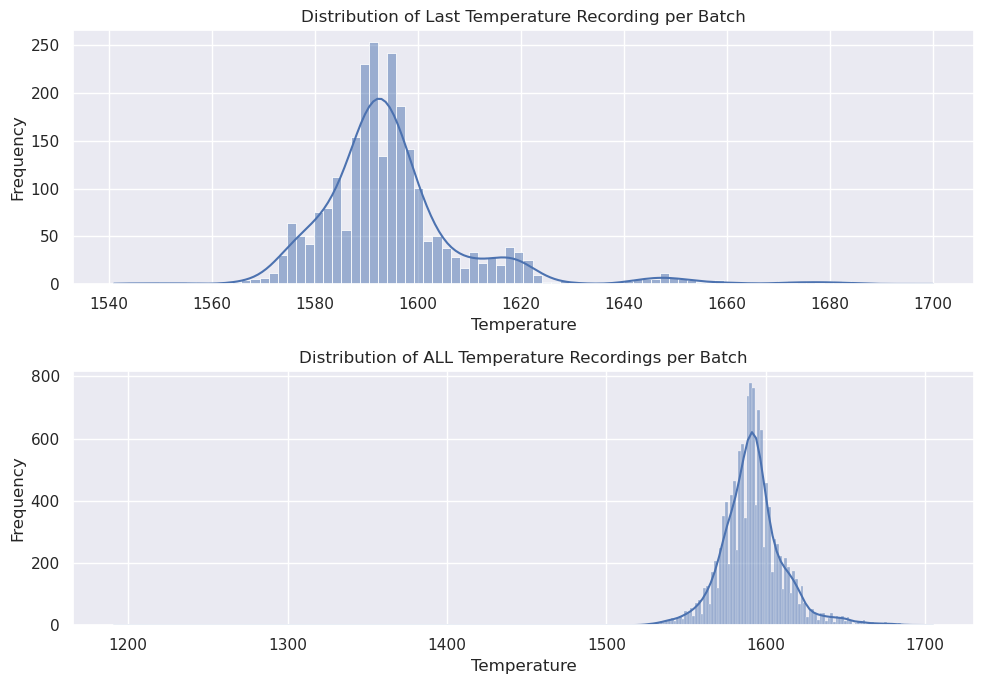

In [56]:
fig, axes = plt.subplots(2,1,figsize=(10,7))

sns.histplot(max_temp_per_key,x='temperature',discrete=False,kde=True,ax=axes[0])
axes[0].set_title("Distribution of Last Temperature Recording per Batch")
axes[0].set_xlabel("Temperature")
axes[0].set_ylabel("Frequency")

sns.histplot(data_temp_en,x='temperature',discrete=False,kde=True,ax=axes[1])
axes[1].set_title("Distribution of ALL Temperature Recordings per Batch")
axes[1].set_xlabel("Temperature")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [57]:
print("Distribuição somente das últimas medidas de temperatura:\n",max_temp_per_key.loc[(max_temp_per_key['sampling_no'] != 1),'temperature'].describe())
print("Distribuição de todas as medidas de temperatura, inclusive as últimas:\n",data_temp_en.loc[(data_temp_en['sampling_no'] != 1),'temperature'].describe())
print("Distribuição de todas as medidas de temperatura, exceto as últimas:\n",data_temp_en.loc[(data_temp_en['sampling_no'] != 1) & (~data_temp_en.index.isin(max_temp_per_key.index)),'temperature'].describe())

Distribuição somente das últimas medidas de temperatura:
 count    2475.000000
mean     1595.336162
std        16.023153
min      1541.000000
25%      1587.000000
50%      1593.000000
75%      1599.000000
max      1700.000000
Name: temperature, dtype: float64
Distribuição de todas as medidas de temperatura, inclusive as últimas:
 count    9790.000000
mean     1592.908172
std        17.988920
min      1383.000000
25%      1583.000000
50%      1592.000000
75%      1600.000000
max      1705.000000
Name: temperature, dtype: float64
Distribuição de todas as medidas de temperatura, exceto as últimas:
 count    7315.000000
mean     1592.086671
std        18.536217
min      1383.000000
25%      1581.000000
50%      1591.000000
75%      1601.000000
max      1705.000000
Name: temperature, dtype: float64
